<a href="https://colab.research.google.com/github/SynBioExplorer/SynBio_NLP_analysis/blob/main/New_NLP_analysis_of_synthetic_biology.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



# **Library import**

In [ ]:
!pip install pandas-profiling
!pip install torch
!pip install geopy
!pip install chart_studio

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 324.4/324.4 kB 21.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 352.3/352.3 kB 35.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 102.7/102.7 kB 13.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 679.5/679.5 kB 56.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.5/296.5 kB 33.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.4/455.4 kB 50.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.7/4.7 MB 129.4 MB/s eta 0:00:00
  Created wheel for htmlmin: filename=htmlmin-0.1.12-py3-none-any.whl size=27081 sha256=e036fe01dd79c492db722a4339701ae46c0070d1a5e0d92eaf10a9a223b09487
  Stored in directory: /root/.cache/pip/wheels/dd/91/29/a79cecb328d01739e64017b6fb9a1ab9d8cb1853098ec5966d
Successfully built htmlmin
  Attem

In [ ]:
import pandas as pd
import numpy as np
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go
from matplotlib import pyplot as plt
from matplotlib import cm
import re


In [ ]:
#from pandas_profiling import ProfileReport
from datetime import datetime
#from umap import UMAP


In [ ]:
import chart_studio
chart_studio.tools.set_credentials_file(username='xxx', api_key='xxx')
import chart_studio.plotly as py


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# **Data preprocessing**

In [ ]:
#import data
file1=pd.read_excel('/content/drive/MyDrive/Coding data/expanded_query.xlsx')
old_query=pd.read_excel('/content/drive/MyDrive/Coding data/18k_articles.xlsx')

In [ ]:
len(file1)

29862

In [ ]:
file1=file1.drop_duplicates(subset=['Article Title'])

In [ ]:
len(file1)

29412

In [ ]:
file1['Document Type'].value_counts()

Article                             17569
Review                               4357
Meeting Abstract                     3516
Article; Book Chapter                 938
Editorial Material                    877
Proceedings Paper                     768
Review; Book Chapter                  322
Article; Proceedings Paper            264
Article; Early Access                 260
News Item                             159
Correction                             78
Review; Early Access                   66
Letter                                 58
Editorial Material; Book Chapter       55
Book                                   40
Note                                   28
Book Review                            27
Editorial Material; Early Access        8
Article; Data Paper                     6
Reprint                                 4
Biographical-Item                       2
Article; Retracted Publication          2
Software Review                         2
Bibliography                      

In [ ]:
file1['Document Type'].unique()

array(['Article', 'Article; Early Access', 'Review; Early Access',
       'Review', 'Correction', 'Editorial Material', 'Meeting Abstract',
       'Article; Book Chapter', 'Article; Proceedings Paper',
       'Database Review', 'News Item', 'Bibliography',
       'Proceedings Paper', 'Book Review', 'Review; Book Chapter',
       'Editorial Material; Book Chapter', 'Note',
       'Editorial Material; Early Access', 'Letter', 'Book',
       'Biographical-Item', 'Article; Data Paper', 'Reprint',
       'Article; Book', 'Correction, Addition',
       'Article; Retracted Publication', 'Software Review',
       'News Item; Early Access', 'Retraction'], dtype=object)

In [ ]:
D=['Article', 'Article; Early Access', 'Review; Early Access','Review','Article; Book Chapter','Article; Proceedings Paper','Proceedings Paper','Review; Book Chapter','Article; Book','Article; Data Paper']
file1=file1[file1['Document Type'].isin(D)]
#J=['J','C','S','']
#file1=file1[file1['Publication Type'].isin(J)]

In [ ]:
len(file1)

24551

In [ ]:
#drop all empty columns
file1=file1.drop(labels=['Unnamed: 0','Book Authors','Book Editors','Book Group Authors','Book Author Full Names','Group Authors','Book Series Title','Book Series Subtitle','Language','Conference Sponsor','Affiliations','Researcher Ids','ORCIDs','Funding Name Preferred','Cited References','Publisher','Publisher City','Publisher Address','ISSN','eISSN','Journal Abbreviation','ISBN','Volume','Issue','Part Number', 'Supplement','Special Issue', 'Meeting Abstract', 'Start Page', 'End Page','Article Number','Reprint Addresses','Funding Text','DOI Link','Early Access Date','Number of Pages','WoS Categories', 'Web of Science Index','IDS Number','Open Access Designations','Highly Cited Status', 'Hot Paper Status', 'Date of Export','Web of Science Record'],axis=1)
#only columns where abstract and publication year is not 0 (=drop 100 rows)
file1 = file1[file1['Abstract'].notna()]
file1 = file1[file1['Publication Year'].notna()]
file1 = file1[file1['Authors'].notna()]
file1 = file1[file1['Addresses'].notna()]
file1.reset_index(drop=True)

,Publication Type,Authors,Author Full Names,Article Title,Source Title,Document Type,Conference Title,Conference Date,Conference Location,Conference Host,...,180 Day Usage Count,Since 2013 Usage Count,Journal ISO Abbreviation,Publication Date,Publication Year,DOI,Book DOI,Research Areas,Pubmed Id,UT (Unique WOS ID)
0,J,"Cai, HW; Zhang, YZ; Xu, JC; Zhu, LH; Cheng, KS...","Cai, HW; Zhang, YZ; Xu, JC; Zhu, LH; Cheng, KS...",Polymorphism at the esterase isozyme locus Est...,GENES & GENETIC SYSTEMS,Article,NaN,NaN,NaN,NaN,...,0,6,Genes Genet. Syst.,AUG,2003.0,10.1266/ggs.78.285,NaN,Biochemistry & Molecular Biology; Genetics & H...,14532707.0,WOS:000186795400002
1,J,"Hayano, A; Amano, M; Miyazaki, N","Hayano, A; Amano, M; Miyazaki, N",Phylogeography and population structure of the...,GENES & GENETIC SYSTEMS,Article,NaN,NaN,NaN,NaN,...,0,8,Genes Genet. Syst.,FEB,2003.0,NaN,NaN,Biochemistry & Molecular Biology; Genetics & H...,12655140.0,WOS:000182480100008
2,J,"Honda, M; Ota, H; Kohler, G; Ineich, I; Chirio...","Honda, M; Ota, H; Kohler, G; Ineich, I; Chirio...",Phylogeny of the lizard subfamily Lygosominae ...,GENES & GENETIC SYSTEMS,Article,NaN,NaN,NaN,NaN,...,0,8,Genes Genet. Syst.,FEB,2003.0,10.1266/ggs.78.71,NaN,Biochemistry & Molecular Biology; Genetics & H...,12655139.0,WOS:000182480100007
3,J,"Onodera, R; Seki, M; Ui, A; Satoh, Y; Miyajima...","Onodera, R; Seki, M; Ui, A; Satoh, Y; Miyajima...",Functional and physical interaction between Sg...,GENES & GENETIC SYSTEMS,Article,NaN,NaN,NaN,NaN,...,1,2,Genes Genet. Syst.,FEB,2002.0,10.1266/ggs.77.11,NaN,Biochemistry & Molecular Biology; Genetics & H...,12036100.0,WOS:000175625500002
4,J,"Toh-e, A; Oguchi, T","Toh-e, A; Oguchi, T",Defects in glycosylphosphatidylinositol (GPI) ...,GENES & GENETIC SYSTEMS,Article,NaN,NaN,NaN,NaN,...,0,2,Genes Genet. Syst.,DEC,2001.0,10.1266/ggs.76.393,NaN,Biochemistry & Molecular Biology; Genetics & H...,11922108.0,WOS:000174495300006
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23306,J,"Yadav, VG; Stephanopoulos, G","Yadav, Vikramaditya G.; Stephanopoulos, Gregory",Reevaluating synthesis by biology,CURRENT OPINION IN MICROBIOLOGY,Review,NaN,NaN,NaN,NaN,...,0,19,Curr. Opin. Microbiol.,JUN,2010.0,10.1016/j.mib.2010.04.002,NaN,Microbiology,20447859.0,WOS:000279302600018
23307,J,"Zeng, BX; Yao, MD; Wang, Y; Xiao, WH; Yuan, YJ","Zeng, Bo-Xuan; Yao, Ming-Dong; Wang, Ying; Xia...",Metabolic Engineering of Saccharomyces cerevis...,FRONTIERS IN BIOENGINEERING AND BIOTECHNOLOGY,Article,NaN,NaN,NaN,NaN,...,9,49,Front. Bioeng. Biotechnol.,MAR 17,2020.0,10.3389/fbioe.2020.00152,NaN,Biotechnology & Applied Microbiology; Science ...,32258005.0,WOS:000525699500001
23308,J,"Zhuang, Y; Yang, GY; Chen, XH; Liu, Q; Zhang, ...","Zhuang, Yu; Yang, Guang-Yu; Chen, Xiaohui; Liu...",Biosynthesis of plant-derived ginsenoside Rh2 ...,METABOLIC ENGINEERING,Article,NaN,NaN,NaN,NaN,...,17,195,Metab. Eng.,JUL,2017.0,10.1016/j.ymben.2017.04.009,NaN,Biotechnology & Applied Microbiology,28479190.0,WOS:000405854400004
23309,J,"Held, HA; Roychowdhury, A; Benner, SA","Held, HA; Roychowdhury, A; Benner, SA",C-5 modified nucleosides: Direct insertion of ...,NUCLEOSIDES NUCLEOTIDES & NUCLEIC ACIDS,Article,NaN,NaN,NaN,NaN,...,0,12,Nucleosides Nucleotides Nucleic Acids,NaN,2003.0,10.1081/NCN-120022030,NaN,Biochemistry & Molecular Biology,12885121.0,WOS:000183927200003


In [ ]:
#for topic model, just look at abstract and publication year
file1['Abstract']=file1['Abstract'].astype(str)
abstracts_df=file1[['Abstract','Publication Year']]
abstracts_df=abstracts_df.rename(columns={'Publication Year':'Publication_Year'})

#format and remove special characters from text
abstracts_df.Abstract = abstracts_df.apply(lambda row: re.sub(r"http\S+", "", row.Abstract).lower(), 1)
abstracts_df.Abstract = abstracts_df.apply(lambda row: " ".join(filter(lambda x:x[0]!="@", row.Abstract.split())), 1)
abstracts_df.Abstract = abstracts_df.apply(lambda row: " ".join(re.sub("[^a-zA-Z]+", " ", row.Abstract).split()), 1)
timestamps = abstracts_df.Publication_Year.to_list()
docs = abstracts_df.Abstract.to_list()

In [ ]:
#ProfileReport(file1) #EDA, good for exploratory data anlayis

In [ ]:
from google.colab import files

file1.to_excel('processed.xlsx')
files.download('processed.xlsx')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Comparison to Scopus query**

In [ ]:
scopus=pd.read_csv('/content/drive/MyDrive/Coding data/scopus.csv')
file1=pd.read_excel('/content/drive/MyDrive/Coding data/18k_articles.xlsx')

In [ ]:
J=['J']
file1=file1[file1['Publication Type'].isin(J)]
sco=['Article','Review']
scopus=scopus[scopus['Document Type'].isin(sco)]
scopus=scopus.dropna(subset=['PubMed ID'])
scopus['PubMed ID']=scopus['PubMed ID'].astype('int64')
file1=file1.dropna(subset=['DOI'])
scopus=scopus.dropna(subset=['DOI'])

In [ ]:
import pandas as pd
from matplotlib import pyplot as plt
from matplotlib_venn import venn2
from matplotlib_venn import venn3

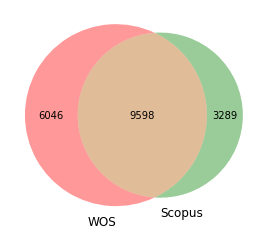

In [ ]:
#overlap between journal articles of Scopus and Web of Science dataset
venn2([set(file1['DOI'].to_list()),
       set(scopus['DOI'].to_list())],
       set_labels=('WOS', 'Scopus')
     )

# **World Cloud**

In [ ]:
!pip install wordcloud
from wordcloud import WordCloud

In [ ]:
txt=file1['Keywords Plus'].str.cat(sep=', ')

news_wordcloud = WordCloud( width = 800, height = 800,
                background_color ='white',
                collocations=False,
                min_font_size = 10).generate(txt)

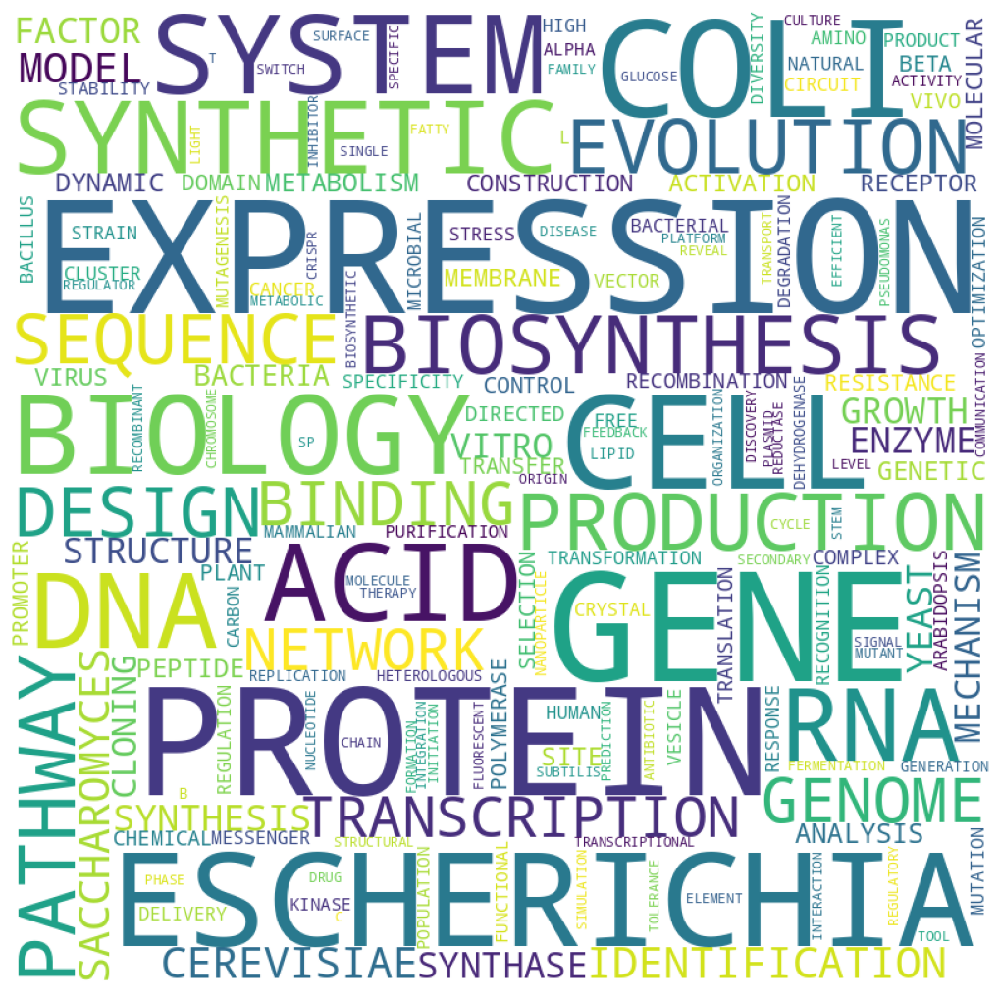

In [ ]:
#wordcloud of most frequent topics in abstracts of Web of Science Dataset
import matplotlib.pyplot as plt
%matplotlib inline
plt.figure(figsize = (10, 10), facecolor = 'None')
plt.imshow(news_wordcloud)
plt.axis("off")
plt.tight_layout(pad = 0)
plt.savefig('wordcloud.png')
plt.show()

# **Histogram of publication counts**

In [ ]:
file1['Publication Year'].value_counts()

In [ ]:
file2=file1[['Publication Year','Article Title']]
file2=file2.rename(columns={'Publication Year':'Year','Article Title':'Count'})
file2=file2.groupby(['Year']).count().reset_index()
file2=file2.loc[11:33]
file2


,Year,Count
11,2000.0,173
12,2001.0,139
13,2002.0,163
14,2003.0,171
15,2004.0,174
16,2005.0,204
17,2006.0,243
18,2007.0,294
19,2008.0,287
20,2009.0,421


In [ ]:
fig = px.bar(file2, x='Year',y='Count', template= 'xgridoff',labels={'Year':'Publication year','Count':'Publication count'}, width=500, height=500 )
fig.update_layout(xaxis_range=[1999,2023], plot_bgcolor='white', xaxis_color='black', yaxis_color='black')
fig.update_xaxes(tickcolor='black', showgrid=False, gridcolor='lightgray', showline=True, linewidth=2, linecolor='black')
fig.update_yaxes(tickcolor='black', showgrid=False, gridcolor='lightgray', showline=True, linewidth=2, linecolor='black')
fig.show()
fig.write_html('pubmed_hist.html')

# **Topic Modelling**

In [ ]:
#!pip install --upgrade joblib==1.1.0
!pip install umap-learn
!pip install sentence-transformers
#!pip install pytorch
!pip install bertopic
#!pip install https://github.com/pandas-profiling/pandas-profiling/archive/master.zip
!pip install bertopic[visualization]
!pip install hdbscan
!pip install https:://github.com/huggingface/transformers/
!pip install openai

In [ ]:
from bertopic import BERTopic

In [ ]:
from hdbscan import HDBSCAN
from sklearn.cluster import KMeans
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import CountVectorizer
from bertopic.representation import MaximalMarginalRelevance
from bertopic.vectorizers import ClassTfidfTransformer
import openai
from bertopic.representation import OpenAI

In [ ]:
from umap import UMAP

In [ ]:
#specify the model parameters

# Step 1 - Extract embeddings
sentence_model = SentenceTransformer("all-mpnet-base-v2")
#embeddings = sentence_model.encode(docs, show_progress_bar=True)
# Step 2 - Reduce dimensionality
umap_model = UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric='cosine')
# Step 3 - Cluster reduced embeddings
hdbscan_model = HDBSCAN(min_cluster_size=15, metric='euclidean', cluster_selection_method='eom', prediction_data=True)
# Step 4 - Tokenize topics
vectorizer_model = CountVectorizer(ngram_range=(1, 3), stop_words="english")
# Step 5 - Create topic representation
ctfidf_model = ClassTfidfTransformer()
# Step 6 - Fine-tune topic representations
representation_model = MaximalMarginalRelevance(diversity=0.3)
# Create your representation model
#openai.api_key = 'sk-REDACTED'
openai.api_key ='xxxx'
representation_model = OpenAI(model="gpt-3.5-turbo", chat=True, exponential_backoff=True)

In [ ]:
# specify parameters for BERTopic model
topic_model = BERTopic(
  calculate_probabilities=True,
  nr_topics=100,                            # limit to 100 topics
  embedding_model=sentence_model,           # Step 1 - embedd sentences into vector space
  umap_model=umap_model,                    # Step 2 - Reduce dimensionality
  hdbscan_model=hdbscan_model,              # Step 3 - Cluster reduced embeddings
  vectorizer_model=vectorizer_model,        # Step 4 - Tokenize topics
  ctfidf_model=ctfidf_model,                # Step 5 - Extract topic words
  representation_model=representation_model # Step 6 - (Optional) Fine-tune topic represenations
)


In [ ]:
# train and fit the model to the WOS dataset
topics, probs = topic_model.fit_transform(docs)

In [ ]:
# Reduce outliers
new_topics = topic_model.reduce_outliers(docs, topics)

In [ ]:
topic_model.update_topics(docs, topics=new_topics)

In [ ]:
#topic modelling results with respective frequency
topic_model.get_topic_info()

,Topic,Count,Name,Representation,Representative_Docs
0,0,2143,0_metabolic_production_pathway_engineering,"[metabolic, production, pathway, engineering, ...",[bio based production of industrially importan...
1,1,987,1_biology_synthetic_research_science,"[biology, synthetic, research, science, and, l...",[synthetic biology is an emerging area of rese...
2,2,893,2_rna_translation_trna_mrna,"[rna, translation, trna, mrna, the, of, we, th...",[expansion of the genetic code allows unnatura...
3,3,664,3_cyanobacteria_photosynthetic_pcc_microalgae,"[cyanobacteria, photosynthetic, pcc, microalga...",[cyanobacteria provide an interesting platform...
4,4,1501,4_circuits_biological_synthetic_design,"[circuits, biological, synthetic, design, biol...",[synthetic biology builds upon the techniques ...
...,...,...,...,...,...
94,94,20,94_ige_allergen_allergic_allergy,"[ige, allergen, allergic, allergy, fel, allerg...",[the induction of blocking igg antibodies that...
95,95,25,95_gsh_cys_ptpase_adp,"[gsh, cys, ptpase, adp, ribosylation, max, nm,...",[site directed mutagenesis of a synthetic gene...
96,96,22,96_methylation_imprinted_imprinting_epigenetic,"[methylation, imprinted, imprinting, epigeneti...",[genomic imprinting is a term used for an inte...
97,97,25,97_ubiquitin_cdc_ubiquitination_ub,"[ubiquitin, cdc, ubiquitination, ub, parkin, p...",[background techniques that harness the power ...


In [ ]:
topic_labels = topic_model.generate_topic_labels(topic_prefix=True, separator=" ")
topic_model.set_topic_labels(topic_labels)

In [ ]:
#topic modelling results with respective frequency
topic_model.get_topic_info()

,Topic,Count,Name,CustomName,Representation,Representative_Docs
0,0,2143,0_metabolic_production_pathway_engineering,1 biology synthetic research,"[metabolic, production, pathway, engineering, ...",[bio based production of industrially importan...
1,1,987,1_biology_synthetic_research_science,2 rna translation trna,"[biology, synthetic, research, science, and, l...",[synthetic biology is an emerging area of rese...
2,2,893,2_rna_translation_trna_mrna,3 cyanobacteria photosynthetic pcc,"[rna, translation, trna, mrna, the, of, we, th...",[expansion of the genetic code allows unnatura...
3,3,664,3_cyanobacteria_photosynthetic_pcc_microalgae,4 circuits biological synthetic,"[cyanobacteria, photosynthetic, pcc, microalga...",[cyanobacteria provide an interesting platform...
4,4,1501,4_circuits_biological_synthetic_design,5 biosynthetic natural products,"[circuits, biological, synthetic, design, biol...",[synthetic biology builds upon the techniques ...
...,...,...,...,...,...,...
94,94,20,94_ige_allergen_allergic_allergy,95 gsh cys ptpase,"[ige, allergen, allergic, allergy, fel, allerg...",[the induction of blocking igg antibodies that...
95,95,25,95_gsh_cys_ptpase_adp,96 methylation imprinted imprinting,"[gsh, cys, ptpase, adp, ribosylation, max, nm,...",[site directed mutagenesis of a synthetic gene...
96,96,22,96_methylation_imprinted_imprinting_epigenetic,97 ubiquitin cdc ubiquitination,"[methylation, imprinted, imprinting, epigeneti...",[genomic imprinting is a term used for an inte...
97,97,25,97_ubiquitin_cdc_ubiquitination_ub,98 graphene nanoparticles silver,"[ubiquitin, cdc, ubiquitination, ub, parkin, p...",[background techniques that harness the power ...


In [ ]:
#save model
topic_model.save('/content/drive/MyDrive/Coding data/08-06-23-gpt')
#load model
#topic_model=BERTopic.load('/content/drive/MyDrive/Coding data/gpt_04_maybe')

In [ ]:
#download the topics to a csv file
df=topic_model.get_topic_info()
df.to_csv('08-06-topics-gpt.csv')
from google.colab import files
files.download("08-06-topics-gpt.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
#document level visualisation of topic clusters (useful for verification)
fig=topic_model.visualize_documents(docs,hide_annotations=True)
fig.update_layout(plot_bgcolor='white', xaxis_color='black', yaxis_color='black',width=1500,height=1500)
fig.show()
fig.write_html('doc_vis3.html')

In [ ]:
hierarchical_topics = topic_model.hierarchical_topics(docs)


100%|██████████| 98/98 [00:00<00:00, 113.32it/s]


In [ ]:
fig=topic_model.visualize_hierarchy(color_threshold=0.9, custom_labels=True)
fig.show()
fig.write_html('hiearchy_color_threshold2.html')
py.plot(fig, filename = 'hierarchy', auto_open=True)

'https://plotly.com/~SynBio/127/'

In [ ]:
#visualise hierarchy on document level with addional topics
fig = topic_model.visualize_hierarchical_documents(docs, hierarchical_topics, custom_labels=True)
fig.show()
fig.write_html('hierarchicalTopicVis.html')

In [ ]:
 #top 100 (all) topics
top100=topic_model.get_topic_info()
top100=top100.sort_values(by='Count', ascending=False)
top100lst=top100.Topic.tolist()
topic_model._outliers = 0
fig=topic_model.visualize_heatmap(width=1250, height=1250, custom_labels=True)
fig.update_layout(font=dict(family="Verdana",size=6))
fig.show()

fig.write_html('heatmap.html')
py.plot(fig, filename = 'heatmap', auto_open=True)

'https://plotly.com/~SynBio/95/'

In [ ]:
#only top 50 most frequent topics
top50=topic_model.get_topic_info()
top50=top50.sort_values(by='Count', ascending=False)
top50=top50.iloc[0:50]
top50lst=top50.Topic.tolist()
fig=topic_model.visualize_heatmap(topics=top50lst,width=1250,height=1250,custom_labels=True)
fig.write_html('heatmap_top50_.html')
fig.show()
py.plot(fig, filename = 'heatmap_top50', auto_open=True)

'https://plotly.com/~SynBio/99/'

# **Dynamic Topic Modelling**

In [ ]:
#calculate topic over time (re-calculates topic label for each year but displays overall label)
dynamic_topics = topic_model.topics_over_time(docs, timestamps)

In [ ]:
dynamic_topics.to_csv('dynamic_topics_gpt.csv')
files.download("dynamic_topics_gpt.csv")

NameError: ignored

In [ ]:
#import data
gpt_topics=pd.read_csv('/content/drive/MyDrive/Coding data/08-06-topics-gpt.csv')
dynamic_topics=pd.read_csv('/content/drive/MyDrive/Coding data/dynamic_topics_gpt.csv')

In [ ]:
dynamic_topics

,Unnamed: 0,Topic,Words,Frequency,Timestamp
0,0,16,"athletes, endurance, ec, olympic, frequencies",1,1984.0
1,1,2,"trna, asp, unmodified, molecules, aspartylation",1,1990.0
2,2,18,"sex, foundresses, fecundities, patch, allocations",1,1990.0
3,3,26,"diandrus, paleas, rigidus, lemmas, scabrid",1,1990.0
4,4,58,"ang, tsp, ii, vsmcs, pdgf",1,1990.0
...,...,...,...,...,...
2021,2021,83,"mitogenome, editing, ppr, plastome, sativa",1,2023.0
2022,2022,85,"serum, dendrimer, cargo, dendrimers, delivery",1,2023.0
2023,2023,86,"archaea, archaeal, crenarchaeota, euryarchaeot...",1,2023.0
2024,2024,90,"egcg, epidermis, guard, pea, electron",1,2023.0


In [ ]:
#data preprocessing:
dynamic_topics=dynamic_topics.drop(['Unnamed: 0'],axis=1)
dynamic_topics=dynamic_topics.rename(columns={'CustomName':'Original_Definition'})
gpt_topics=gpt_topics.rename(columns={'CustomName':'Original_Definition'})
gpt_topics=gpt_topics.reset_index()
gpt_topics=gpt_topics.rename(columns={'Count':'index_by_total_occurance'})
dynamic_topics['Timestamp']=dynamic_topics.Timestamp.astype(int)
sums=dynamic_topics.groupby('Timestamp').agg({'Frequency':'sum'})
sums=sums.reset_index()
sums=sums.rename(columns={'Frequency':'Total_count'})
dynamic_topics=dynamic_topics.merge(sums, how='left',on='Timestamp')
dynamic_topics['Topic_percentage']=dynamic_topics['Frequency']/dynamic_topics['Total_count']*100
dynamic_topics['Topic_percentage']=dynamic_topics['Topic_percentage'].round(decimals=2)
dynamic_topics=dynamic_topics.loc[(dynamic_topics['Timestamp']>1999)& (dynamic_topics['Timestamp']<2022)]
dynamic_topics=dynamic_topics.merge(gpt_topics,how='left', on='Topic')
dynamic_topics=dynamic_topics.drop(['Unnamed: 0'],axis=1)

In [ ]:
dynamic_topics.head()

,Topic,Words,Frequency,Timestamp,Total_count,Topic_percentage,index,index_by_total_occurance,Name,Original_Definition,Representation,Representative_Docs
0,2,"mcmu, tertiary, mcmum, isoacceptor, methylcarb...",1,2000,173,0.58,2,893,2_rna_translation_trna_mrna,2 rna translation trna,"['rna', 'translation', 'trna', 'mrna', 'the', ...",['expansion of the genetic code allows unnatur...
1,3,"plastid, ps, plastoquinone, cbbx, photosystem",2,2000,173,1.16,3,664,3_cyanobacteria_photosynthetic_pcc_microalgae,3 cyanobacteria photosynthetic pcc,"['cyanobacteria', 'photosynthetic', 'pcc', 'mi...",['cyanobacteria provide an interesting platfor...
2,4,"circuits, simulator, information, heap, benchmark",5,2000,173,2.89,4,1501,4_circuits_biological_synthetic_design,4 circuits biological synthetic,"['circuits', 'biological', 'synthetic', 'desig...",['synthetic biology builds upon the techniques...
3,5,"thanatin, oleandomycin, olepks, olep, deoxyole...",3,2000,173,1.73,5,923,5_biosynthetic_natural_products_streptomyces,5 biosynthetic natural products,"['biosynthetic', 'natural', 'products', 'strep...",['a synthetic biology method based on heterolo...
4,6,"nucleatum, pfn, phs, fusobacterium, plasmid",1,2000,173,0.58,6,667,6_crispr_cas_editing_genome,6 crispr cas editing,"['crispr', 'cas', 'editing', 'genome', 'gene',...",['the clustered regularly interspaced short pa...


In [ ]:
import re
import plotly.express as px
import plotly.graph_objects as go
import colorlover as cl
#Graph displaying occurance of topics over time as absolute occurance (e.g. 55 articles with topic 'CRISPR Cas' in 2018)

# extract first 3 words from 'Original_Definition'
dynamic_topics['Topic Description'] = dynamic_topics['Original_Definition'].apply(lambda x: re.sub(r'\d+', '', x))
# get the unique values in 'Topic Description' column
unique_topics = dynamic_topics['Topic Description'].unique()

# create a dictionary with the count of occurrences of each unique topic in 'Topic Description' column
count_dict = {}
for topic in unique_topics:
    count_dict[topic] = dynamic_topics[dynamic_topics['Topic Description'] == topic]['index_by_total_occurance'].iloc[0]

# sort the dictionary by values (count of occurrences)
sorted_dict = dict(sorted(count_dict.items(), key=lambda item: item[1]))

# get the keys of the sorted dictionary in a list
sorted_topics = list(sorted_dict.keys())
#get a custom color palette
pastel_palette = [
    'rgb(102, 197, 204)', 'rgb(246, 207, 113)', 'rgb(248, 156, 116)', 'rgb(220, 176, 242)', 'rgb(135, 197, 95)',
    'rgb(158, 185, 243)', 'rgb(254, 136, 177)', 'rgb(201, 219, 116)', 'rgb(139, 224, 164)', 'rgb(180, 151, 231)',
    'rgb(179, 179, 179)', 'rgb(69, 142, 189)', 'rgb(170, 153, 191)', 'rgb(226, 130, 174)', 'rgb(239, 208, 88)',
    'rgb(224, 151, 144)', 'rgb(180, 98, 134)', 'rgb(115, 167, 187)', 'rgb(106, 176, 67)', 'rgb(109, 126, 159)',
    'rgb(167, 164, 159)', 'rgb(124, 57, 71)', 'rgb(84, 110, 132)', 'rgb(193, 85, 92)', 'rgb(238, 114, 111)'
]
# plot the line chart with modified legend
fig = px.line(dynamic_topics, x='Timestamp', y='Frequency', color='Topic Description',
              hover_data=['Words'],
              labels={'Timestamp':'Publication Year','Frequency':'Number of Publications'},
              category_orders={'Topic Description': sorted_topics[::-1]},
             color_discrete_sequence=pastel_palette) # add the 'category_orders' parameter to the function call
# Add line shapes
fig.add_shape(type='line', x0='2000', y0=-10, x1='2010', y1=-10,
              line=dict(color='#008080', width=2))

fig.add_annotation(x='2007', y=-5, xref='x', yref='y', text='1st Decade',
                   showarrow=False, font=dict(color='#008080', size=12))

fig.add_shape(type='line', x0='2010', y0=-10, x1='2020', y1=-10,
              line=dict(color='#4B0082', width=2))

fig.add_annotation(x='2015', y=-5, xref='x', yref='y', text='2nd Decade',
                   showarrow=False, font=dict(color='#4B0082', size=12))

fig.update_layout(xaxis_range=[2000, 2021], plot_bgcolor='white', xaxis_color='black', yaxis_color='black', width=1000, height=750)
fig.update_xaxes(tickcolor='black', showgrid=False, gridcolor='lightgray', showline=True, linewidth=2, linecolor='black')
fig.update_yaxes(tickcolor='black', showgrid=True, gridcolor='lightgray', showline=True, linewidth=2, linecolor='black')
fig.show()
fig.write_html('/content/dynamic_topic_modelling_absolute.html')
py.plot(fig, filename = 'dynamic_topic_modelling_absolute', auto_open=True)

'https://plotly.com/~SynBio/93/'

In [ ]:
print(px.colors.qualitative.Pastel)

['rgb(102, 197, 204)', 'rgb(246, 207, 113)', 'rgb(248, 156, 116)', 'rgb(220, 176, 242)', 'rgb(135, 197, 95)', 'rgb(158, 185, 243)', 'rgb(254, 136, 177)', 'rgb(201, 219, 116)', 'rgb(139, 224, 164)', 'rgb(180, 151, 231)', 'rgb(179, 179, 179)']


In [ ]:
import re
import plotly.express as px
#Graph highlighting the percentage distribution per year of the total corpus of each topic per year
# e.g. What percentage of papers published in 2019 deal with 'CRISPR-Cas'


# extract first 3 words from 'Original_Definition'
dynamic_topics['Topic Description'] = dynamic_topics['Original_Definition'].apply(lambda x: re.match(r'^[^\s]+(\s+[^\s]+){0,2}', x).group() if re.match(r'^[^\s]+(\s+[^\s]+){0,2}', x) else '')

# get the unique values in 'Topic Description' column
unique_topics = dynamic_topics['Topic Description'].unique()

# create a dictionary with the count of occurrences of each unique topic in 'Topic Description' column
count_dict = {}
for topic in unique_topics:
    count_dict[topic] = dynamic_topics[dynamic_topics['Topic Description'] == topic]['index_by_total_occurance'].iloc[0]

# sort the dictionary by values (count of occurrences)
sorted_dict = dict(sorted(count_dict.items(), key=lambda item: item[1]))

# get the keys of the sorted dictionary in a list
sorted_topics = list(sorted_dict.keys())

# plot the line chart with modified legend
fig = px.line(dynamic_topics, x='Timestamp', y='Topic_percentage', color='Topic Description',
              hover_data=['Topic Description'],
              labels={'Topic_percentage': 'Percentage per year','Timestamp':'Publication Year'},
              category_orders={'Topic Description': sorted_topics},color_discrete_sequence=pastel_palette) # add the 'category_orders' parameter to the function call
fig.update_layout(xaxis_range=[2000, 2022], yaxis_range=[0, 50], plot_bgcolor='white',
                  xaxis_color='black', yaxis_color='black', width=1000, height=750)
fig.update_xaxes(tickcolor='black', showgrid=False, gridcolor='lightgray', showline=True, linewidth=2, linecolor='black')
fig.update_yaxes(tickcolor='black', showgrid=True, gridcolor='lightgray', showline=True, linewidth=2, linecolor='black')
fig.show()
fig.write_html('/content/dynamic_topic_modelling_linegraph.html')
py.plot(fig, filename = 'dynamic_topic_modelling_linegraph', auto_open=True)

'https://plotly.com/~SynBio/91/'

In [ ]:
#Graph depicting the share of topics over time as part of the whole corpus per year with the defintions from the static model
import plotly.graph_objs as go

fig = go.Figure(
    go.Bar(
        x=dynamic_topics['Timestamp'],
        y=dynamic_topics['Topic_percentage'],
        marker_color=dynamic_topics['Topic'],
        text=dynamic_topics['Topic'],
        hovertemplate='%{text}: %{y:.2f}%<br>Original Definition: %{customdata}',
        textangle=90,
        textposition='inside',
        customdata=dynamic_topics['Original_Definition'],
        name='Topics'
    )
)
fig.update_layout(
    xaxis_title='Publication Year',
    yaxis_title='Percentage',
    xaxis_range=[2000, 2022],
    yaxis_range=[0, 100],
    plot_bgcolor='white',
    xaxis_color='black',
    yaxis_color='black',
    width=1000,
    height=750,
    legend=dict(
        yanchor="top",
        y=0.99,
        xanchor="left",
        x=0.01
    )
)
fig.update_xaxes(
    tickcolor='black',
    showgrid=False,
    gridcolor='lightgray',
    showline=True,
    linewidth=2,
    linecolor='black'
)
fig.update_yaxes(
    tickcolor='black',
    showgrid=True,
    gridcolor='lightgray',
    showline=True,
    linewidth=2,
    linecolor='black'
)
fig.show()
fig.write_html('/content/dynamic_topic_modelling_barchart.html')
py.plot(fig, filename = 'dynamic_topic_modelling_barchart', auto_open=True)

'https://plotly.com/~SynBio/89/'

# **Visualise journals (Which Journals are most popular in the dataset?)**

In [ ]:
#data preparation
subset = file1[['Publication Type','Source Title','Times Cited, All Databases']]

#generate a df that describes mean citiation count
cited_mean=subset.groupby(['Source Title']).mean().reset_index()
cited_mean=cited_mean.rename(columns={'Times Cited, All Databases':'mean_citations','Source Title':'Journal'})
cited_mean.mean_citations=cited_mean.mean_citations.round(decimals=2)
#generate a df that describes total citations per journal
paper_count=subset.groupby(['Source Title']).count().reset_index()
paper_count=paper_count.rename(columns={'Times Cited, All Databases':'Paper_Count','Source Title':'Journal'})
paper_count=paper_count[['Journal','Paper_Count']]
#merge the two dataframes
journals=paper_count.merge(cited_mean,on='Journal')
journals['Journal']=journals['Journal'].str.lower()
journals['Journal'] = journals['Journal'].map(str.title)
journals['Journal'] = journals['Journal'].str.replace('Proceedings Of The National Academy Of Sciences Of The United States Of America','PNAS')
journals['Journal'] = journals['Journal'].str.replace('Plos One','PLOS one')
journals['Journal'] = journals['Journal'].str.replace('Acs Synthetic Biology','ACS Synthetic Biology')
journals['Journal'] = journals['Journal'].str.replace('Acs Nano','ACS Nano')

journals=journals.rename(columns={'mean_citations':"Average Citations"})


<ipython-input-121-d7758e11504e>:5: FutureWarning:

The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.



In [ ]:
journals

,Journal,Paper_Count,Average Citations
0,11Th International Conference On Practical App...,1,0.00
1,12Th International Scientific Conference Engin...,1,0.00
2,16Th International Conference On Scientometric...,1,1.00
3,1St International Conference On Sustainable Pl...,1,5.00
4,2005 44Th Ieee Conference On Decision And Cont...,1,4.00
...,...,...,...
3379,Zhurnal Obshchei Biologii,3,2.67
3380,Zoologica Scripta,1,17.00
3381,Zootaxa,5,8.40
3382,Zuckerindustrie,1,1.00


In [ ]:
#amount of journals in dataset
journals.Journal.nunique()

3375

In [ ]:
#amount of journals in dataset with only one paper
len(journals[journals['Paper_Count'] == 1])


1906

In [ ]:
#what journals publish the most in the field and are those also the ones that have the highest citation count?


#create figure object
fig = px.treemap(journals, path=[px.Constant("Journals"), 'Journal'], values='Paper_Count', color='Average Citations', hover_data=['Average Citations'], color_continuous_scale='agsunset_r')
fig.update_coloraxes(cmax=200, cmin=0,colorbar_orientation = 'h',colorbar_len=0.95)
fig.update_layout(margin=dict(t=50, l=25, r=25, b=25),width=1500,height=1000)
#fig.update_layout(uniformtext=dict(minsize=10, mode='show'))
fig.data[0].textinfo = 'label+text+value'
fig.update_layout(font=dict(family="Arial",size=25 ))
fig.write_html('journal_treemap.html')
fig.show()
py.plot(fig, filename = 'journals', auto_open=True)

'https://plotly.com/~SynBio/77/'

In [ ]:
#journals over time
subset2 = file1[['Publication Type','Source Title','Times Cited, All Databases','Publication Year']]

#remove publication type from df
subset2=subset2.drop(['Publication Type'],axis=1)
#group by year and journal and get paper count + citation sum
subset2 = subset2.groupby(['Publication Year','Source Title']).agg({'Times Cited, All Databases':['count','sum']}).reset_index()
subset2.columns = [' '.join(col) for col in subset2.columns.values]
#rename columns
subset2=subset2.rename(columns={'Times Cited, All Databases count':'Paper Count','Source Title ':'Journal','Times Cited, All Databases sum':'Citation count','Publication Year ':'Publication Year'})
#convert to int
subset2['Publication Year']=subset2['Publication Year'].astype(int)
subset2=subset2[subset2['Paper Count'] >3 ]

In [ ]:
#top 10 papers in terms of citations
top10papers=file1[['Article Title','Source Title','Times Cited, All Databases']].sort_values(by='Times Cited, All Databases', ascending=False)
top10papers[0:10]

,Article Title,Source Title,"Times Cited, All Databases"
3679,RNA-Guided Human Genome Engineering via Cas9,SCIENCE,7190
21283,Enzymatic assembly of DNA molecules up to seve...,NATURE METHODS,5814
10815,Repurposing CRISPR as an RNA-Guided Platform f...,CELL,3347
11093,CRISPR-Mediated Modular RNA-Guided Regulation ...,CELL,2491
18590,Genome-wide essential gene identification in S...,SCIENTIFIC REPORTS,2373
17886,Design and development of polymers for gene de...,NATURE REVIEWS DRUG DISCOVERY,2162
5829,Polyploid incidence and evolution,ANNUAL REVIEW OF GENETICS,1712
27484,Creation of a Bacterial Cell Controlled by a C...,SCIENCE,1694
16901,PROGRAMMED CELL-DEATH INDUCED BY CERAMIDE,SCIENCE,1692
24644,Genome-Scale CRISPR-Mediated Control of Gene R...,CELL,1598


In [ ]:
subset2

In [ ]:
#how much have indidual journals published over time?
fig= px.line(subset2, x='Publication Year',y='Paper Count',color='Journal', title='individual journal popularity over time',render_mode='SVG',line_shape='spline',markers=True
             ,color_discrete_sequence=px.colors.qualitative.Pastel)#,animation_frame="Journal")
fig.update_layout(width=750, height=750,showlegend=False)#,yaxis_range=[0,200])
fig.update_xaxes(nticks=25)
fig.update_yaxes(tickvals=[0,25,50,75,100,200,300,400])
fig.update_layout(xaxis_range=[2005,2021], plot_bgcolor='white', xaxis_color='black', yaxis_color='black')
fig.update_xaxes(tickcolor='black', showgrid=False, gridcolor='lightgray', showline=True, linewidth=2, linecolor='black')
fig.update_yaxes(tickcolor='black', showgrid=True, gridcolor='lightgray', showline=True, linewidth=2, linecolor='black')
fig.show()


In [ ]:
#how much have different journals published over time and how many times have these papers been cited?
fig = px.scatter(subset2, x='Publication Year',y='Journal',size='Paper Count',color='Citation count',render_mode='SVG',color_continuous_scale='agsunset_r')
fig.update_layout(width=900, height=700,showlegend=True,yaxis=dict(tickfont =dict(size=3)))
fig.update_yaxes(showticklabels=True,showgrid=True,ticks="outside")
fig.update_layout(xaxis_range=[2005,2021], plot_bgcolor='white', xaxis_color='black', yaxis_color='black')
fig.update_xaxes(tickcolor='black', showgrid=False, gridcolor='lightgray', showline=True, linewidth=2, linecolor='black')
fig.update_yaxes(tickcolor='black', showgrid=True, gridcolor='lightgray', showline=True, linewidth=2, linecolor='black')

fig.show()


In [ ]:
#How strongly are time of publication and citation count correlated across all papers?
fig = px.scatter(file1, x='Publication Year',y='Times Cited, All Databases',
                 render_mode='SVG',color='Times Cited, All Databases',
                 log_y=True,color_continuous_scale='agsunset_r', trendline="ols",
                 hover_data=['Article Title','Source Title'],
                 labels={'Times Cited, All Databases':'Citation count','Source Title':'Journal'}, )
fig.update_layout(showlegend=False,xaxis_range=[2005,2021],width=750, height=750)
fig.update_coloraxes(cmax=250,cmin=0)
#fig.update_yaxes(tickvals=[0,25,50,100,250,500,750,3500])
#fig.update_yaxes(showticklabels=True,showgrid=True,ticks="outside")
fig.update_layout(xaxis_range=[2005,2021], plot_bgcolor='white', xaxis_color='black', yaxis_color='black')
fig.update_xaxes(tickcolor='black', showgrid=False, gridcolor='lightgray', showline=True, linewidth=2, linecolor='black')
fig.update_yaxes(tickcolor='black', showgrid=True, gridcolor='lightgray', showline=True, linewidth=2, linecolor='black')

fig.show()
fig.write_html('allcitations.html')

In [ ]:
#Does 180 day usage count influence total citation count?
fig = px.scatter(file1, x='180 Day Usage Count',y='Times Cited, All Databases',color='Publication Year',
                color_continuous_scale='agsunset', trendline="ols",
                 hover_data=['Article Title','Source Title'],
                 labels={'Times Cited, All Databases':'Citation count','Source Title':'Journal'} )
fig.update_coloraxes(cmax=2020, cmin=2000)
fig.update_layout(yaxis_range=[0,500],xaxis_range=[0,180], plot_bgcolor='white', xaxis_color='black', yaxis_color='black')
fig.update_xaxes(tickcolor='black', showgrid=False, gridcolor='lightgray', showline=True, linewidth=2, linecolor='black')
fig.update_yaxes(tickcolor='black', showgrid=True, gridcolor='lightgray', showline=True, linewidth=2, linecolor='black')
fig.update_layout(font=dict(family="Arial",size=30 ))
fig.show()
fig.write_html('supplemary_fig_180_use_citation_cnt.html')

# ***Where do articles come from geographically?***

In [ ]:
#locations
locations = file1[['Addresses','Article Title','Times Cited, All Databases','Publication Year']]
locations
#remove everything between square brackets
locations['Addresses']=locations['Addresses'].str.replace('\[.*?\]','',regex=True)
#split columns Addresses at ';', so that collaborators in each paper get an individual row(
locations=locations.assign(Addresses=locations.Addresses.str.split(';')).explode('Addresses')
#format everything in UK
locations['Addresses'] = locations['Addresses'].str.replace('Scotland','United Kingdom').str.replace('England','United Kingdom').str.replace('USA','United States')
locations['Paper ID']=locations.index

In [ ]:
#list of cities from an open data base
#https://simplemaps.com/data/world-cities
cities = pd.read_csv('/content/drive/MyDrive/Coding data/worldcities.csv')
#drop really short city names (only 3 letter names since they give false positives later on) and cities with less than 20k
cities=cities[cities['city_ascii'].str.len()>4]
cities

cities

,city,city_ascii,lat,lng,country,iso2,iso3,admin_name,capital,population,id
0,Tokyo,Tokyo,35.6839,139.7744,Japan,JP,JPN,Tōkyō,primary,39105000.0,1392685764
1,Jakarta,Jakarta,-6.2146,106.8451,Indonesia,ID,IDN,Jakarta,primary,35362000.0,1360771077
2,Delhi,Delhi,28.6667,77.2167,India,IN,IND,Delhi,admin,31870000.0,1356872604
3,Manila,Manila,14.6000,120.9833,Philippines,PH,PHL,Manila,primary,23971000.0,1608618140
4,São Paulo,Sao Paulo,-23.5504,-46.6339,Brazil,BR,BRA,São Paulo,admin,22495000.0,1076532519
...,...,...,...,...,...,...,...,...,...,...,...
42899,Agapa,Agapa,71.4504,89.2500,Russia,RU,RUS,Krasnoyarskiy Kray,NaN,10.0,1643009087
42900,Tukchi,Tukchi,57.3670,139.5000,Russia,RU,RUS,Khabarovskiy Kray,NaN,10.0,1643472801
42901,Numto,Numto,63.6667,71.3333,Russia,RU,RUS,Khanty-Mansiyskiy Avtonomnyy Okrug-Yugra,NaN,10.0,1643985006
42903,Timmiarmiut,Timmiarmiut,62.5333,-42.2167,Greenland,GL,GRL,Kujalleq,NaN,10.0,1304206491


In [ ]:
#define function to return city name from open source db list if it matches something in the address from the locations setting
def find_city(title, list_cities):
    title_lower = title.lower()
    for city in list_cities:
        if city.lower() in title_lower:
            return city

#make 2 lists with the relevant columns
list_cities=cities['city_ascii']
address_list=locations['Addresses'].squeeze()
title=address_list.astype(str)

#apply function to new column
locations['city_ascii'] = [find_city(title, list_cities) for title in address_list]


In [ ]:
#do the same for country
def find_country(title, country_list):
    title_lower = title.lower()
    for country in country_list:
        if country.lower() in title_lower:
            return country
#make 2 lists with the relevant columns
country_list=cities['country']
address_list=locations['Addresses'].squeeze()
title=address_list.astype(str)
#apply function to new column
locations['country'] = [find_country(title, country_list) for title in address_list]

In [ ]:
#merge two dataframes
locations_merged=pd.merge(locations,cities, how='left',on=['city_ascii','country'])
#Problem: too many matches (duplicates in city list (Machester UK, Manchester USA)), 77k rows instead of 46k
#sort by Addresses and population size
locations_merged=locations_merged.sort_values(['Addresses','population'],ascending=False)
#drop duplicates (only keep the first one with the largest population)
locations_merged=locations_merged.drop_duplicates(subset=['Addresses','Article Title'], keep='first')
#add paper number
#drop unnessesary columns,sort, and reformat index
locations_merged=locations_merged[['Paper ID','Addresses', 'Article Title', 'Times Cited, All Databases', 'Publication Year', 'city', 'country', 'lat', 'lng']]
locations_merged=locations_merged.sort_values('Paper ID')
locations_merged=locations_merged.reset_index(drop=True)

In [ ]:
locations_merged

,Paper ID,Addresses,Article Title,"Times Cited, All Databases",Publication Year,city,country,lat,lng
0,0,"China Agr Univ, Coll Plant Sci & Technol, Dept...",Polymorphism at the esterase isozyme locus Est...,3,2003.0,Beijing,China,39.9040,116.4075
1,0,"Acad Sinica, Inst Genet, Beijing 100081, Peop...",Polymorphism at the esterase isozyme locus Est...,3,2003.0,Beijing,China,39.9040,116.4075
2,0,"Yunnan Acad Agr, Kunming 650205, Peoples R China",Polymorphism at the esterase isozyme locus Est...,3,2003.0,Kunming,China,25.0433,102.7061
3,1,"Kyoto Univ, Grad Sch Sci, Dept Zool, Kyoto 606...",Phylogeography and population structure of the...,17,2003.0,Kyōto,Japan,35.0117,135.7683
4,1,"Univ Tokyo, Ocean Res Inst, Otsuchi Marine Re...",Phylogeography and population structure of the...,17,2003.0,Tokyo,Japan,35.6839,139.7744
...,...,...,...,...,...,...,...,...,...
68863,29776,"Univ Tennessee, Dept Civil & Environm Engn, K...",Frequency domain analysis of noise in autoregu...,157,2003.0,Knoxville,United States,35.9692,-83.9496
68864,29776,"Oak Ridge Natl Lab, Mol Scale Engn & Nanoscale...",Frequency domain analysis of noise in autoregu...,157,2003.0,Oak Ridge,United States,35.9639,-84.2938
68865,29776,"Univ Tennessee, Ctr Environm Biotechnol, Knox...",Frequency domain analysis of noise in autoregu...,157,2003.0,Knoxville,United States,35.9692,-83.9496
68866,29777,"Wake Forest Univ, Dept Biol, Winston Salem, NC...",tRNA(2)(Gln) mutants that translate the CGA ar...,13,1998.0,Salem,United States,44.9231,-123.0246


In [ ]:
fig = px.scatter_geo(locations_merged,lat='lat',lon='lng',hover_name="Article Title")
fig.update_layout(title = 'World map', title_x=0.5)
fig.show()

In [ ]:
fig = px.density_mapbox(locations_merged,lat='lat',lon='lng', hover_name ='city',
                              z="Times Cited, All Databases",radius=7,
                        center=dict(lat=0, lon=0), zoom=0,width=900, height=700,color_continuous_scale='agsunset_r',
                        mapbox_style='carto-positron')
fig.update_layout(title='Worldwide Citation Count', title_x=0.5)

fig.show()


In [ ]:
#group by country and year
locations_grouped_country = locations_merged.groupby(['Publication Year','country']).agg({'Times Cited, All Databases':['count','sum']}).reset_index()
locations_grouped_country.columns = [' '.join(col) for col in locations_grouped_country.columns.values]
locations_grouped_country=locations_grouped_country.rename(columns={'Times Cited, All Databases count':'Paper Count','Times Cited, All Databases sum':'Citation Count','Publication Year ':'Publication Year'})
locations_grouped_country['Publication Year']=locations_grouped_country['Publication Year'].astype(int)
locations_grouped_country['Citations Per Paper']=locations_grouped_country['Citation Count']/locations_grouped_country['Paper Count']
locations_grouped_country['Citations Per Paper']=locations_grouped_country['Citations Per Paper'].round(2)

In [ ]:
locations_grouped_country


,Publication Year,country,Paper Count,Citation Count,Citations Per Paper
0,1984,Canada,1,12,12.00
1,1990,Australia,1,10,10.00
2,1990,France,1,127,127.00
3,1990,Switzerland,1,26,26.00
4,1990,United States,2,120,60.00
...,...,...,...,...,...
1420,2023,Turkey,3,0,0.00
1421,2023,Ukraine,1,0,0.00
1422,2023,United Kingdom,95,44,0.46
1423,2023,United States,407,175,0.43


In [ ]:
#only format all countries with less than 250 total publications as other
valuecnt=locations_merged.country.value_counts()
valuecnt=pd.DataFrame(data=valuecnt)
valuecnt=valuecnt.reset_index()
valuecnt=valuecnt.rename(columns={'index':'country','country':'publication_count'})
valuecnt.loc[valuecnt.publication_count < 250, ['country']]='other'
valuecnt

,country,publication_count
0,United States,20826
1,China,10045
2,United Kingdom,5493
3,Germany,4141
4,Japan,3968
5,other,3161
6,South Korea,3108
7,France,1767
8,Australia,1583
9,Denmark,1459


In [ ]:
#make a pie chart from valuecnt
fig = px.pie(valuecnt,values='publication_count',names='country',color_discrete_sequence=px.colors.qualitative.Pastel, labels='country')
fig.update_layout(showlegend=False,plot_bgcolor='white', xaxis_color='black', yaxis_color='black')
fig.update_traces(textposition='inside', textinfo='percent+label')
fig.update_layout(font=dict(family="Arial",size=30 ))
fig.show()
fig.write_html('pie_chart_countrie.html')

In [ ]:
top15 = [
'United States'
,'China'
,'United Kingdom'
,'Germany'
,'Japan'
,'other'
,'South Korea'
,'France'
,'Australia'
,'Denmark'
,'Canada'
,'Spain'
,'Italy'
,'Netherlands'
,'India'
,'Switzerland']

array(['United States', 'China', 'United Kingdom', 'Germany',
       'South Korea', 'Japan', 'Denmark', 'Australia', 'France', 'Canada',
       'Spain', 'Netherlands', 'Switzerland', 'Italy', 'Singapore',
       'India', 'Russia', 'Belgium', 'Austria', 'Sweden', 'Mexico',
       'Taiwan', 'Brazil', 'Israel', 'other'], dtype=object)

In [ ]:
others['country'].unique()

array(['Russia', 'Singapore', 'Brazil', 'Mexico', 'Sweden', 'Israel',
       'Taiwan', 'Belgium', 'Austria', 'Iran', 'Chile', 'Portugal'],
      dtype=object)

In [ ]:
#countries with less than 1000 publications
others=locations_merged.country.value_counts()
others=pd.DataFrame(data=others)
others=others.reset_index()
others=others.rename(columns={'index':'country','country':'publication_count'})
others=others.loc[others.publication_count < 1000]
others.country.unique()

In [ ]:
#countries not in top 15
countrieslessthan250=['Russia', 'Singapore', 'Brazil', 'Mexico', 'Sweden', 'Israel',
       'Taiwan', 'Belgium', 'Austria', 'Iran', 'Chile', 'Portugal']

In [ ]:
#group by country and year but only include top 10 countries
locations_merged2 = locations_merged
locations_merged2.country=locations_merged2.country.replace(countrieslessthan250,'other')
locations_grouped_country2 = locations_merged2.groupby(['Publication Year','country']).agg({'Times Cited, All Databases':['count','sum']}).reset_index()
locations_grouped_country2.columns = [' '.join(col) for col in locations_grouped_country2.columns.values]
locations_grouped_country2=locations_grouped_country2.rename(columns={'Times Cited, All Databases count':'Paper Count','Times Cited, All Databases sum':'Citation Count','Publication Year ':'Publication Year'})
locations_grouped_country2['Publication Year']=locations_grouped_country2['Publication Year'].astype(int)
locations_grouped_country2['Citations Per Paper']=locations_grouped_country2['Citation Count']/locations_grouped_country2['Paper Count']
locations_grouped_country2['Citations Per Paper']=locations_grouped_country2['Citations Per Paper'].round(2)


In [ ]:
#graph showing all publications over time for top 15 countries with a defined color set and legend order
import plotly.express as px

fig = px.line(locations_grouped_country2, x="Publication Year", y="Paper Count", color='country ', markers=False,
            color_discrete_map=
{'United States': '#66c5cc',
'China': '#f6cf71',
'United Kingdom': '#f89c74',
'Germany': '#dcb0f2',
'South Korea': '#87c55f',
'Japan': '#fe88b1',
'Denmark': '#c9db74',
'Australia': '#8be0a4',
'France': '#b497e7',
'Canada': '#b3b3b3',
'Spain': '#e9957e',
'Italy': '#b7e0ef',
'Netherlands': '#f0c674',
'India': '#f2b1c6',
'Switzerland': '#f7c295',
'other': '#9eb9f3'})
fig.update_layout(xaxis_range=[2005,2021], plot_bgcolor='white', xaxis_color='black', yaxis_color='black')
fig.update_xaxes(tickcolor='black', showgrid=False, gridcolor='lightgray', showline=True, linewidth=2, linecolor='black')
fig.update_yaxes(tickcolor='black', showgrid=False, gridcolor='lightgray', showline=True, linewidth=2, linecolor='black')
fig.update_layout(font=dict(family="Arial",size=30))
fig.update_layout(legend=dict(traceorder='normal'))
fig.update_layout(legend=dict(yanchor="top",y=0.99,xanchor="left",x=0.01))
fig.data = sorted(fig.data, key=lambda x: ['United States'
,'China'
,'United Kingdom'
,'Germany'
,'Japan'
,'South Korea'
,'France'
,'Australia'
,'Denmark'
,'Canada'
,'Spain'
,'Italy'
,'Netherlands'
,'India'
,'Switzerland'
,'other'].index(x.name))

fig.show()
fig.write_html('countries_over_time_others.html')


In [ ]:
#citation count of countries over time
fig = px.line(locations_grouped_country, x="Publication Year",y='Citation Count',color='country ',color_discrete_sequence=px.colors.qualitative.Pastel)
fig.update_layout(xaxis_range=[2005,2021], plot_bgcolor='white', xaxis_color='black', yaxis_color='black')
fig.update_xaxes(tickcolor='black', showgrid=False, gridcolor='lightgray', showline=True, linewidth=2, linecolor='black')
fig.update_yaxes(tickcolor='black', showgrid=False, gridcolor='lightgray', showline=True, linewidth=2, linecolor='black')

fig.show()

In [ ]:
# boxplot of top 15 countries cumulative publications
locations_merged_filtered = locations_merged.loc[(locations_merged['Publication Year'] > 2004) & (locations_merged['Publication Year']<2023)]
locations_merged_filtered.country=locations_merged_filtered.country.replace(countrieslessthan250,'other')
locations_merged_filtered = locations_merged[locations_merged['country'].isin(top15)]

fig = px.box(locations_merged_filtered,y='Times Cited, All Databases',x='country',log_y=True,labels={'Times Cited, All Databases':'Citation Count'},color='country',
              color_discrete_map=
{'United States': '#66c5cc',
'China': '#f6cf71',
'United Kingdom': '#f89c74',
'Germany': '#dcb0f2',
'South Korea': '#87c55f',
'Japan': '#fe88b1',
'Denmark': '#c9db74',
'Australia': '#8be0a4',
'France': '#b497e7',
'Canada': '#b3b3b3',
'Spain': '#e9957e',
'Italy': '#b7e0ef',
'Netherlands': '#f0c674',
'India': '#f2b1c6',
'Switzerland': '#f7c295',
'other': '#9eb9f3'})
fig.update_layout(showlegend=False,plot_bgcolor='white', xaxis_color='black', yaxis_color='black')
fig.update_xaxes(tickcolor='black', showgrid=False, gridcolor='lightgray', showline=True, linewidth=2, linecolor='black',categoryorder='array',categoryarray=[
'United States'
,'China'
,'United Kingdom'
,'Germany'
,'Japan'
,'South Korea'
,'France'
,'Australia'
,'Denmark'
,'Canada'
,'Spain'
,'Italy'
,'Netherlands'
,'India'
,'Switzerland'
,'other'])
fig.update_yaxes(tickcolor='black', showgrid=False, gridcolor='lightgray', showline=True, linewidth=2, linecolor='black')
fig.update_layout(font=dict(family="Arial",size=30 ),xaxis_title=None)

fig.show()
fig.write_html('top10countries_cit_count_desc.html')

<ipython-input-175-6b542c8d1f85>:3: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



In [ ]:
#boxplot of all countries cumulative publications between 2004 and 2021
filtered =locations_merged.loc[(locations_merged['Publication Year'] > 2004) & (locations_merged['Publication Year'] < 2023)]
fig = px.box(filtered,y='Times Cited, All Databases',x='Publication Year',log_y=True,labels={'Times Cited, All Databases':'Citation Count'})
fig.update_layout(xaxis_range=[2004,2023],showlegend=False,plot_bgcolor='white', xaxis_color='black', yaxis_color='black')
fig.update_xaxes(tickcolor='black', showgrid=False, gridcolor='lightgray', showline=True, linewidth=2, linecolor='black')
fig.update_yaxes(tickcolor='black', showgrid=False, gridcolor='lightgray', showline=True, linewidth=2, linecolor='black')
fig.update_layout(font=dict(family="Arial",size=30 ))

fig.show()
fig.write_html('all countries.html')